<a href="https://colab.research.google.com/github/hayafacts/AIML-Lab-Experiment-1/blob/main/Experiment_2_AIML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import heapq
import networkx as nx
import matplotlib.pyplot as plt

# Graph representation: adj_list[node] = [(neighbor, step_cost), ...]
graph = {
    'A': [('B', 6), ('C', 3)],
    'B': [('A', 6), ('D', 3), ('E', 1)],
    'C': [('A', 3), ('E', 5), ('F', 4)],
    'D': [('B', 3), ('G', 3)],
    'E': [('B', 1), ('C', 5), ('G', 6)],
    'F': [('C', 4), ('G', 2)],
    'G': []  # Goal Node
}

# Straight-Line Distance Heuristic h(n) towards Goal 'G'
heuristics = {
    'A': 8,
    'B': 5,
    'C': 6,
    'D': 3,
    'E': 4,
    'F': 2,
    'G': 0
}

In [ ]:
from collections import deque

def bfs(graph, start, goal):
    queue = deque([[start]])
    visited = set()
    nodes_explored = 0

    while queue:
        path = queue.popleft()
        node = path[-1]
        nodes_explored += 1

        if node == goal:
            return path, nodes_explored

        if node not in visited:
            visited.add(node)
            for neighbor, _ in graph.get(node, []):
                new_path = list(path)
                new_path.append(neighbor)
                queue.append(new_path)

    return None, nodes_explored

bfs_path, bfs_nodes = bfs(graph, 'A', 'G')
print("--- Uninformed: Breadth-First Search (BFS) ---")
print(f"Path found: {bfs_path}")
print(f"Nodes explored: {bfs_nodes}\n")

--- Uninformed: Breadth-First Search (BFS) ---
Path found: ['A', 'B', 'D', 'G']
Nodes explored: 11



In [ ]:
def dfs(graph, start, goal):
    stack = [[start]]
    visited = set()
    nodes_explored = 0

    while stack:
        path = stack.pop()
        node = path[-1]
        nodes_explored += 1

        if node == goal:
            return path, nodes_explored

        if node not in visited:
            visited.add(node)
            for neighbor, _ in graph.get(node, []):
                new_path = list(path)
                new_path.append(neighbor)
                stack.append(new_path)

    return None, nodes_explored

dfs_path, dfs_nodes = dfs(graph, 'A', 'G')
print("--- Uninformed: Depth-First Search (DFS) ---")
print(f"Path found: {dfs_path}")
print(f"Nodes explored: {dfs_nodes}\n")

--- Uninformed: Depth-First Search (DFS) ---
Path found: ['A', 'C', 'F', 'G']
Nodes explored: 4



In [ ]:
def greedy_best_first_search(graph, start, goal, h):
    # Priority Queue stores tuples: (h(n), [path_so_far])
    pq = [(h[start], [start])]
    visited = set()
    nodes_explored = 0

    while pq:
        _, path = heapq.heappop(pq)
        node = path[-1]
        nodes_explored += 1

        if node == goal:
            return path, nodes_explored

        if node not in visited:
            visited.add(node)
            for neighbor, _ in graph.get(node, []):
                if neighbor not in visited:
                    new_path = list(path)
                    new_path.append(neighbor)
                    heapq.heappush(pq, (h[neighbor], new_path))

    return None, nodes_explored

greedy_path, greedy_nodes = greedy_best_first_search(graph, 'A', 'G', heuristics)
print("--- Informed: Greedy Best-First Search ---")
print(f"Path found: {greedy_path}")
print(f"Nodes explored: {greedy_nodes}\n")

--- Informed: Greedy Best-First Search ---
Path found: ['A', 'B', 'D', 'G']
Nodes explored: 4



In [ ]:
def a_star_search(graph, start, goal, h):
    # Priority Queue stores: (f(n), g(n), [path_so_far])
    pq = [(h[start], 0, [start])]
    visited = {}
    nodes_explored = 0

    while pq:
        f_cost, g_cost, path = heapq.heappop(pq)
        node = path[-1]
        nodes_explored += 1

        if node == goal:
            return path, g_cost, nodes_explored

        if node not in visited or g_cost < visited[node]:
            visited[node] = g_cost

            for neighbor, cost in graph.get(node, []):
                new_g = g_cost + cost
                new_f = new_g + h[neighbor]
                new_path = list(path)
                new_path.append(neighbor)
                heapq.heappush(pq, (new_f, new_g, new_path))

    return None, float('inf'), nodes_explored

astar_path, astar_cost, astar_nodes = a_star_search(graph, 'A', 'G', heuristics)
print("--- Informed: A* Search ---")
print(f"Optimal Path found: {astar_path}")
print(f"Total Path Cost g(n): {astar_cost}")
print(f"Nodes explored: {astar_nodes}\n")

--- Informed: A* Search ---
Optimal Path found: ['A', 'C', 'F', 'G']
Total Path Cost g(n): 9
Nodes explored: 4



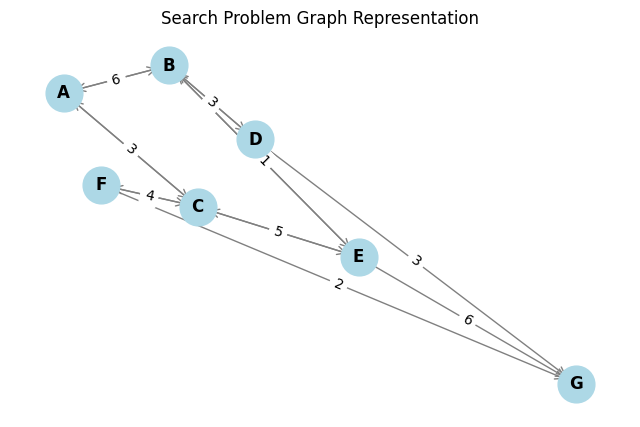

In [ ]:
# Visualize the graph using NetworkX
G = nx.DiGraph()
for node, neighbors in graph.items():
    for neighbor, weight in neighbors:
        G.add_edge(node, neighbor, weight=weight)

pos = nx.spring_layout(G, seed=42)
plt.figure(figsize=(8, 5))

# Draw nodes and edges
nx.draw_networkx_nodes(G, pos, node_size=700, node_color='lightblue')
nx.draw_networkx_labels(G, pos, font_weight='bold')
nx.draw_networkx_edges(G, pos, arrowstyle='->', arrowsize=15, edge_color='gray')

# Draw edge weights (costs)
edge_labels = nx.get_edge_attributes(G, 'weight')
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels)

plt.title("Search Problem Graph Representation")
plt.axis('off')
plt.show()

In [ ]:
import heapq

def uniform_cost_search(graph, start, goal):
    # Priority queue: (cost, current_node, path)
    priority_queue = [(0, start, [])]
    visited = set()

    while priority_queue:
        cost, node, path = heapq.heappop(priority_queue)

        if node in visited:
            continue

        visited.add(node)
        path = path + [node]

        if node == goal:
            return cost, path

        for neighbor, weight in graph[node]:
            if neighbor not in visited:
                heapq.heappush(priority_queue, (cost + weight, neighbor, path))

    return float("inf"), []


# Graph represented as adjacency list
graph = {
    'A': [('B', 1), ('C', 4)],
    'B': [('D', 2), ('E', 5)],
    'C': [('F', 3)],
    'D': [('G', 1)],
    'E': [('G', 2)],
    'F': [('G', 2)],
    'G': []
}

start = 'A'
goal = 'G'

cost, path = uniform_cost_search(graph, start, goal)

if path:
    print("Shortest Path:", " -> ".join(path))
    print("Total Cost:", cost)
else:
    print("Goal not reachable.")

Shortest Path: A -> B -> D -> G
Total Cost: 4


In [ ]:
import heapq

def greedy_best_first_search(graph, heuristic, start, goal):
    # Priority queue: (heuristic, current_node, path, cost)
    pq = [(heuristic[start], start, [start], 0)]

    visited = set()

    while pq:
        h, node, path, cost = heapq.heappop(pq)

        if node in visited:
            continue

        visited.add(node)

        # Goal reached
        if node == goal:
            return path, cost

        # Explore neighbours
        for neighbour, edge_cost in graph[node]:
            if neighbour not in visited:
                new_cost = cost + edge_cost
                heapq.heappush(
                    pq,
                    (heuristic[neighbour],
                     neighbour,
                     path + [neighbour],
                     new_cost)
                )

    return None, float('inf')


# Graph
graph = {
    'A': [('B', 1), ('C', 4)],
    'B': [('D', 2), ('E', 5)],
    'C': [('F', 3)],
    'D': [('G', 1)],
    'E': [('G', 2)],
    'F': [('G', 1)],
    'G': []
}

# Heuristic values
heuristic = {
    'A': 7,
    'B': 6,
    'C': 5,
    'D': 2,
    'E': 3,
    'F': 1,
    'G': 0
}

start = 'A'
goal = 'G'

path, cost = greedy_best_first_search(
    graph, heuristic, start, goal
)

print("Path:", " -> ".join(path))
print("Total Cost:", cost)

Path: A -> C -> F -> G
Total Cost: 8


In [ ]:
from collections import deque

def bfs(graph, start, goal):
    queue = deque([(start, [start], 0)])
    visited = set()

    while queue:
        node, path, cost = queue.popleft()

        if node in visited:
            continue

        visited.add(node)

        # Goal reached
        if node == goal:
            return path, cost

        # Explore neighbours
        for neighbour, edge_cost in graph[node]:
            if neighbour not in visited:
                queue.append(
                    (neighbour,
                     path + [neighbour],
                     cost + edge_cost)
                )

    return None, float('inf')


# Graph
graph = {
    'A': [('B', 1), ('C', 4)],
    'B': [('D', 2), ('E', 5)],
    'C': [('F', 3)],
    'D': [('G', 1)],
    'E': [('G', 2)],
    'F': [('G', 1)],
    'G': []
}

start = 'A'
goal = 'G'

path, cost = bfs(graph, start, goal)

print("Path:", " -> ".join(path))
print("Total Cost:", cost)

Path: A -> B -> D -> G
Total Cost: 4


In [ ]:
def dfs(graph, start, goal):
    stack = [(start, [start], 0)]
    visited = set()

    while stack:
        node, path, cost = stack.pop()

        if node in visited:
            continue

        visited.add(node)

        # Goal reached
        if node == goal:
            return path, cost

        # Add neighbours to stack
        for neighbour, edge_cost in graph[node]:
            if neighbour not in visited:
                stack.append(
                    (neighbour,
                     path + [neighbour],
                     cost + edge_cost)
                )

    return None, float('inf')


# Graph
graph = {
    'A': [('B', 1), ('C', 4)],
    'B': [('D', 2), ('E', 5)],
    'C': [('F', 3)],
    'D': [('G', 1)],
    'E': [('G', 2)],
    'F': [('G', 1)],
    'G': []
}

start = 'A'
goal = 'G'

path, cost = dfs(graph, start, goal)

print("Path:", " -> ".join(path))
print("Total Cost:", cost)

Path: A -> C -> F -> G
Total Cost: 8
